Siddhant Bhalerao

B B3 43

ML Practical-4

In [73]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

In [74]:
df=pd.read_csv("WineQT.csv")

In [75]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [76]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595
1142,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,1597


In [77]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [78]:
df.duplicated().sum()

0

In [79]:
df=df.drop_duplicates()

In [80]:
df.duplicated().sum()

0

In [81]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'Id'],
      dtype='object')

Univariate Analysis

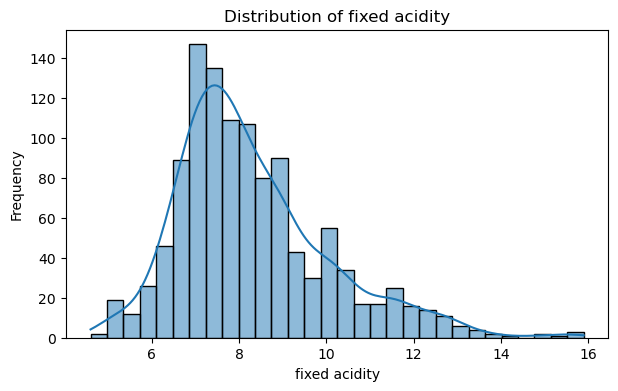

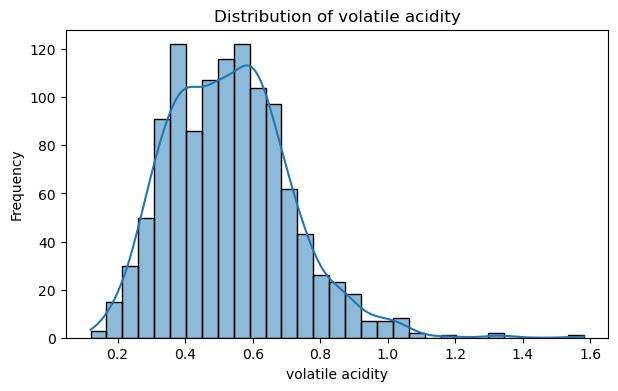

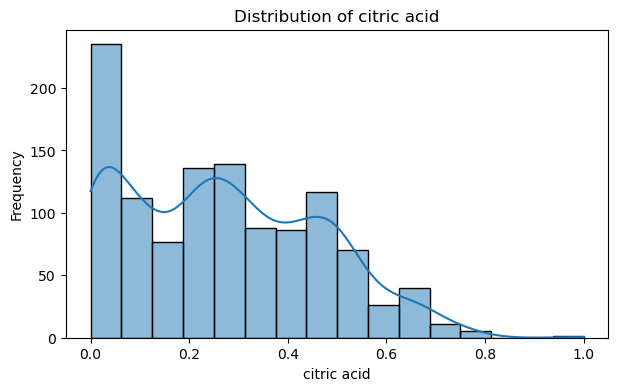

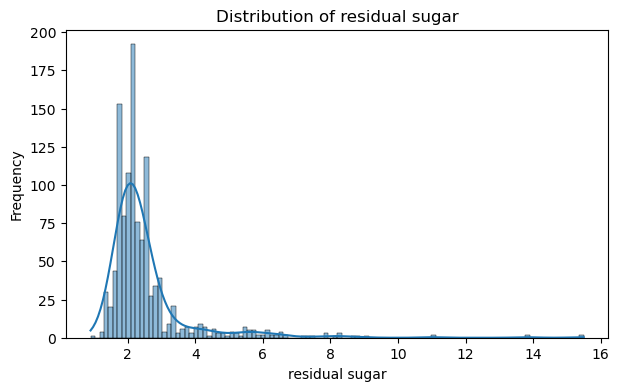

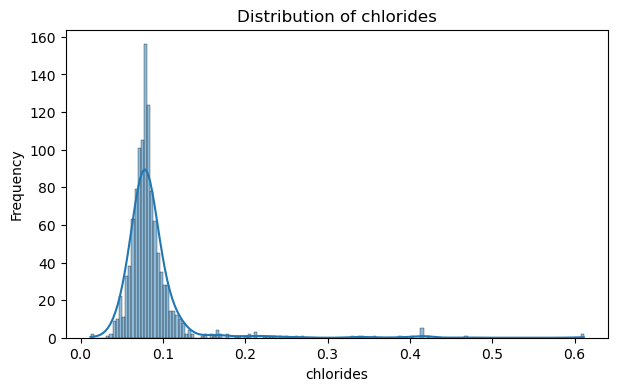

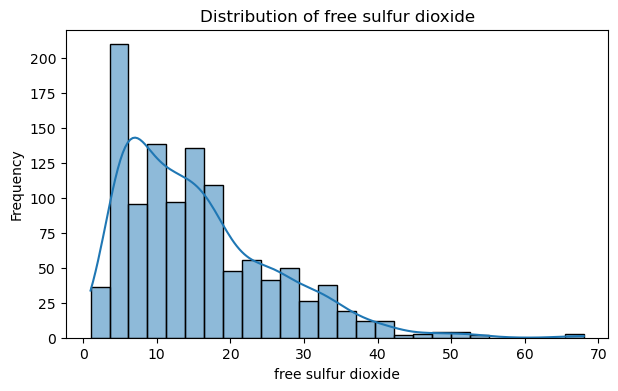

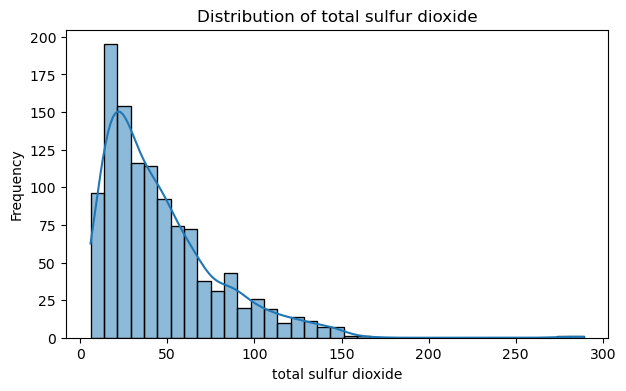

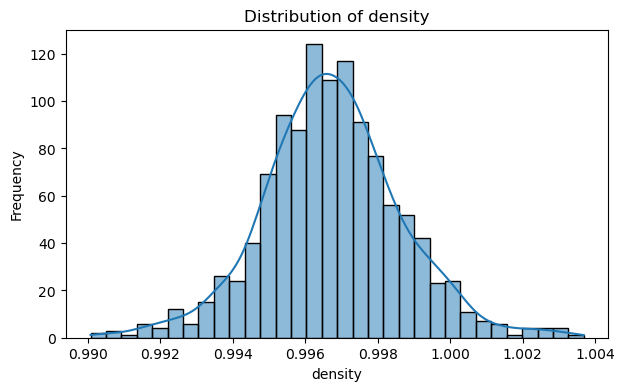

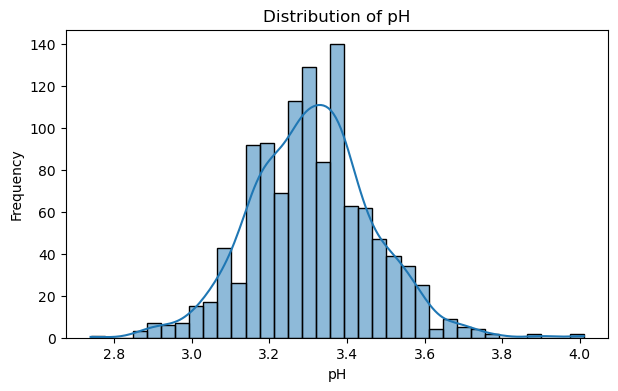

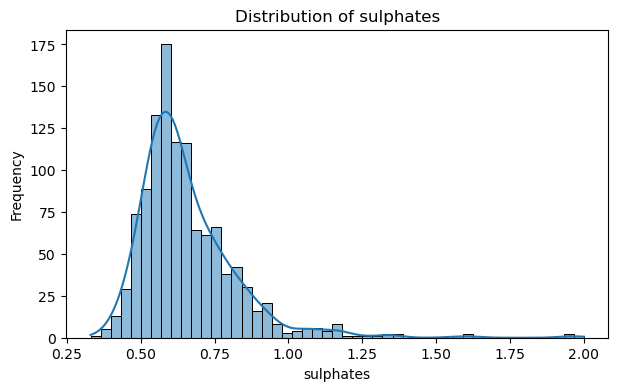

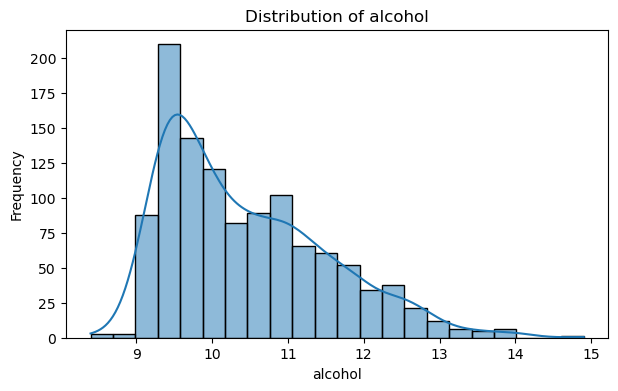

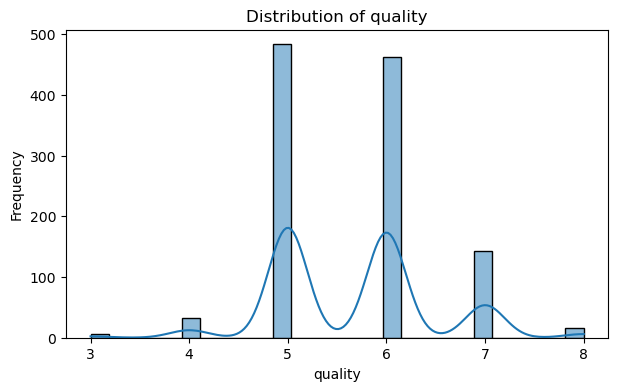

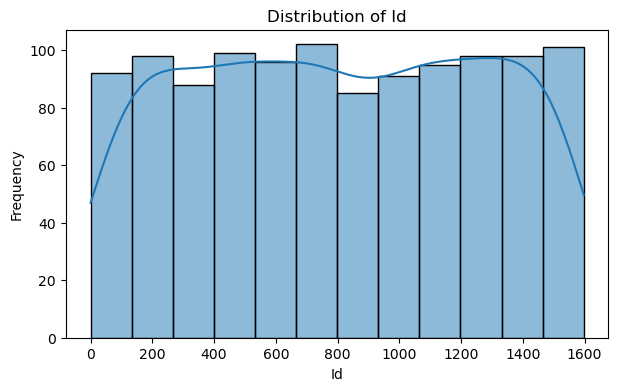

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns
numeric_cols=df.columns
for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col],kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

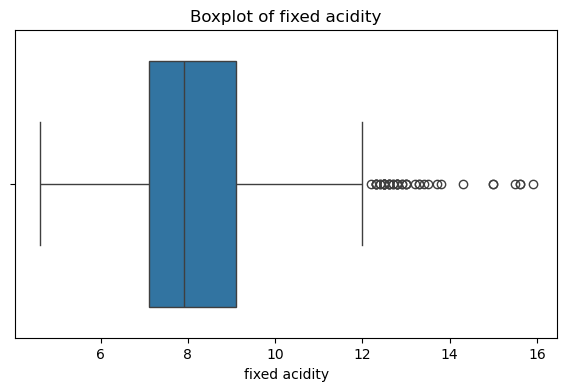

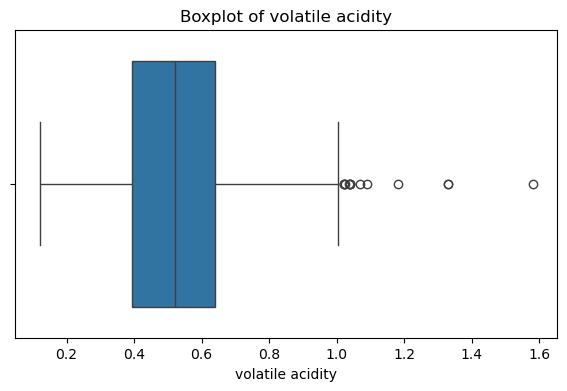

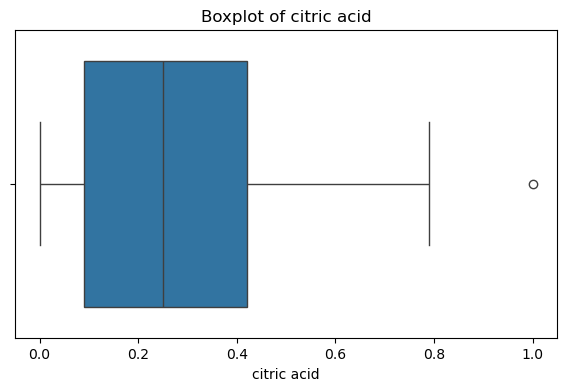

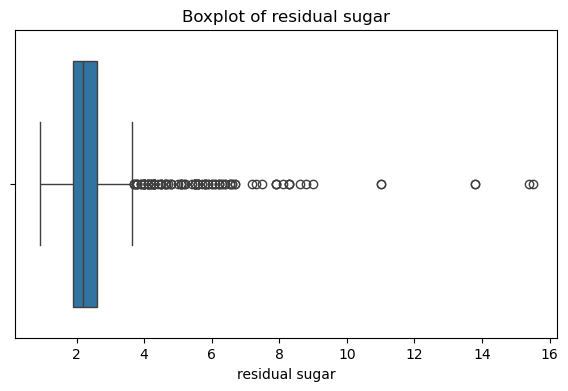

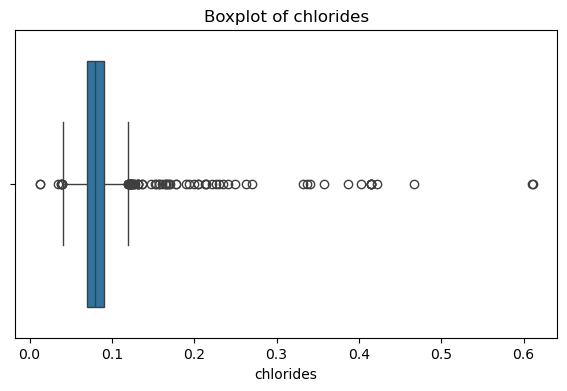

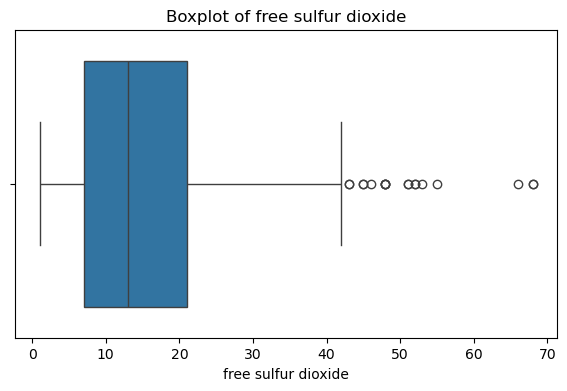

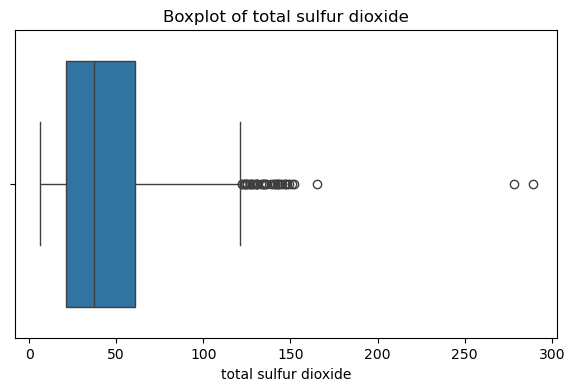

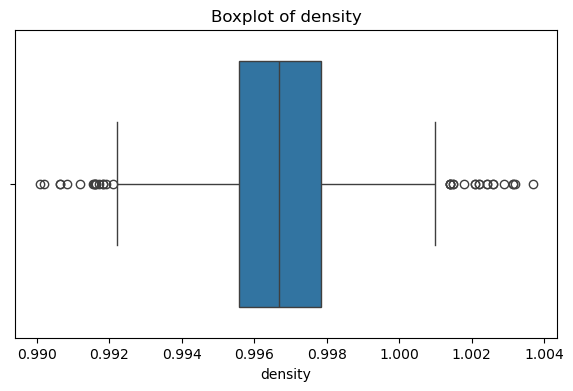

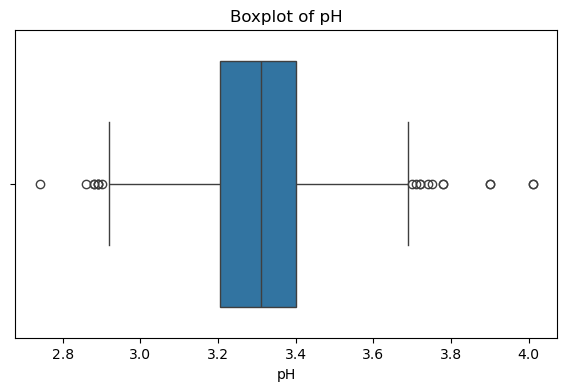

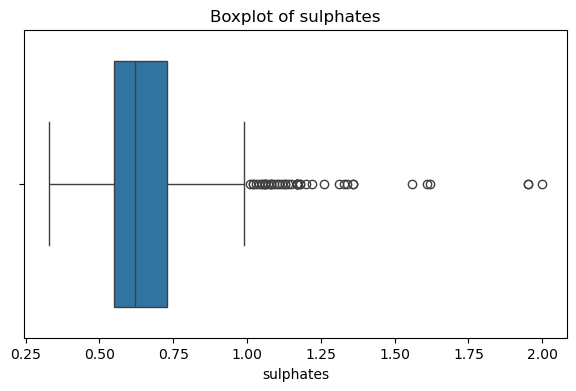

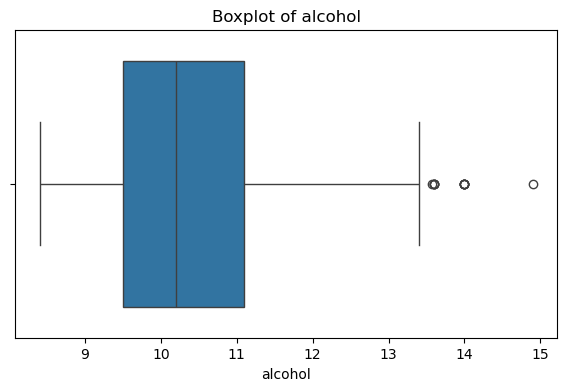

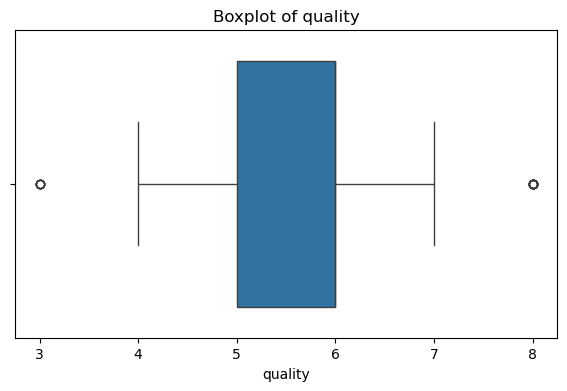

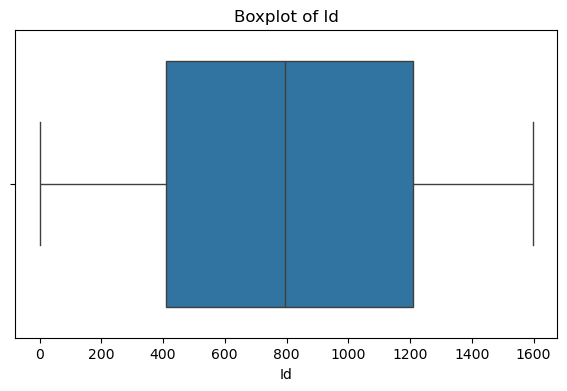

In [83]:
#Boxplot - Outlier Analysis
for col in numeric_cols:
        plt.figure(figsize=(7,4))
        sns.boxplot(x=df[col])
        plt.title(f'Boxplot of {col}')
        plt.show()

In [84]:
#Detect outliers for every feature
features=df.drop(columns=['quality'])
Q1=features.quantile(0.25)
Q3=features.quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
outlier_mask=(features<lower_bound) | (features > upper_bound)
outlier_count=outlier_mask.sum()
outlier_percentage=(outlier_count /len(features))* 100
outlier_summary=pd.DataFrame({
    'Q1':Q1,
    'Q3':Q3,
    'IQR':IQR,
    'Lower Bound':lower_bound,
    'Upper Bound':upper_bound,
    'Outlier Count':outlier_count,
    'Outlier %': outlier_percentage,
})
outlier_summary.round(3)


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
fixed acidity,7.100,9.100,2.000,4.100,12.100,44,3.850
volatile acidity,0.392,0.640,0.248,0.021,1.011,14,1.225
citric acid,0.090,0.420,0.330,-0.405,0.915,1,0.087
residual sugar,1.900,2.600,0.700,0.850,3.650,110,9.624
chlorides,0.070,0.090,0.020,0.040,0.120,77,6.737
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,18,1.575
total sulfur dioxide,21.000,61.000,40.000,-39.000,121.000,40,3.500
density,0.996,0.998,0.002,0.992,1.001,36,3.150
pH,3.205,3.400,0.195,2.913,3.692,20,1.750
sulphates,0.550,0.730,0.180,0.280,1.000,43,3.762


In [85]:
print("Outliers in each feature:\n")
for column in features.columns:
    print(f'{column:25s}:{outlier_count[column]}')

Outliers in each feature:

fixed acidity            :44
volatile acidity         :14
citric acid              :1
residual sugar           :110
chlorides                :77
free sulfur dioxide      :18
total sulfur dioxide     :40
density                  :36
pH                       :20
sulphates                :43
alcohol                  :12
Id                       :0


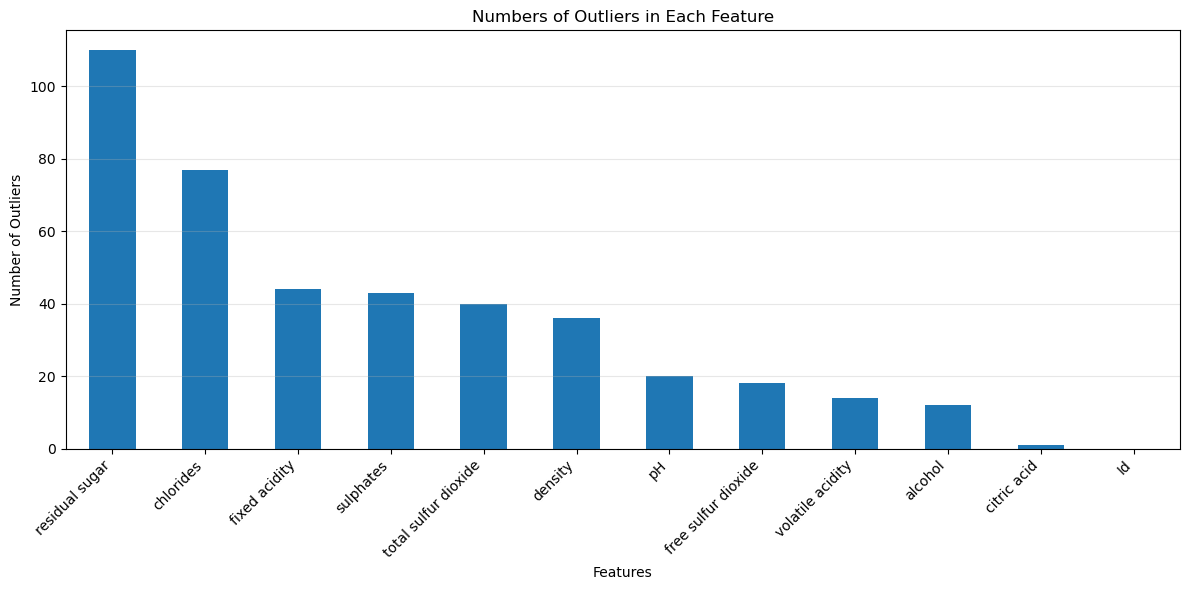

In [86]:
plt.figure(figsize=(12,6))
outlier_count.sort_values(ascending=False).plot(kind='bar')
plt.title("Numbers of Outliers in Each Feature")
plt.xlabel("Features")
plt.ylabel("Number of Outliers")
plt.xticks(rotation=45,ha='right')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()

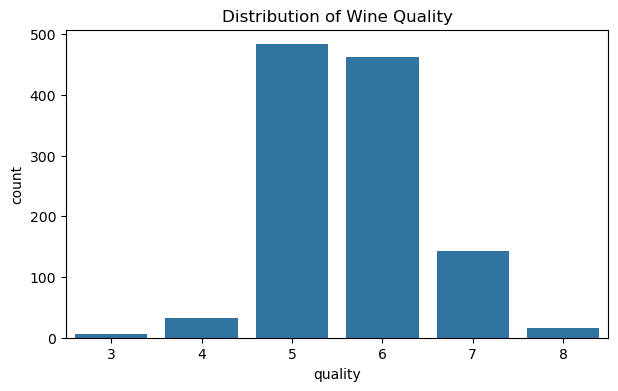

In [87]:
plt.figure(figsize=(7,4))
sns.countplot(x='quality',data=df)
plt.title('Distribution of Wine Quality')
plt.show()

In [88]:
df['quality'].value_counts().sort_index()

quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

2. Bivariate Analysis

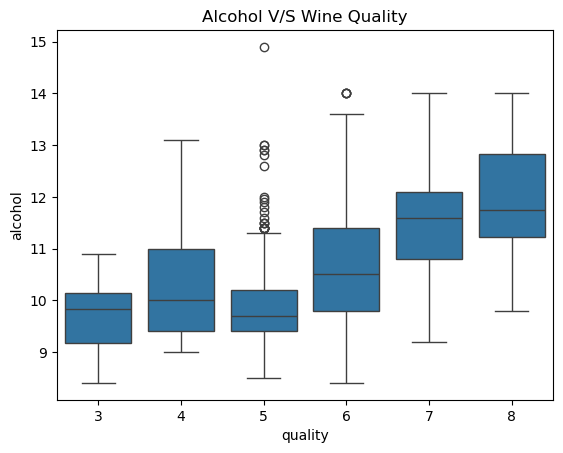

In [89]:
sns.boxplot(x='quality',y='alcohol',data=df)
plt.title('Alcohol V/S Wine Quality')
plt.show()

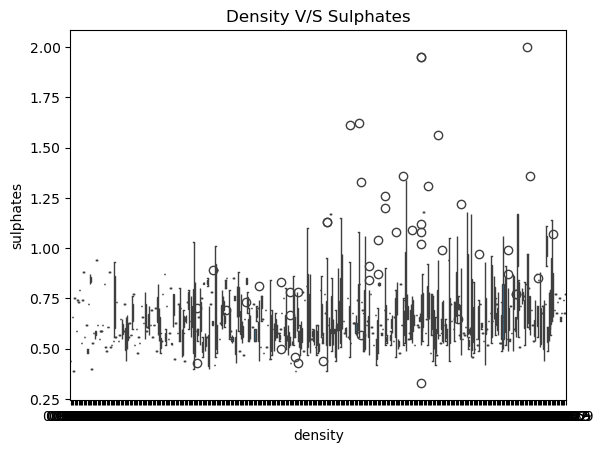

In [90]:
sns.boxplot(x='density',y='sulphates',data=df)
plt.title('Density V/S Sulphates')
plt.show()

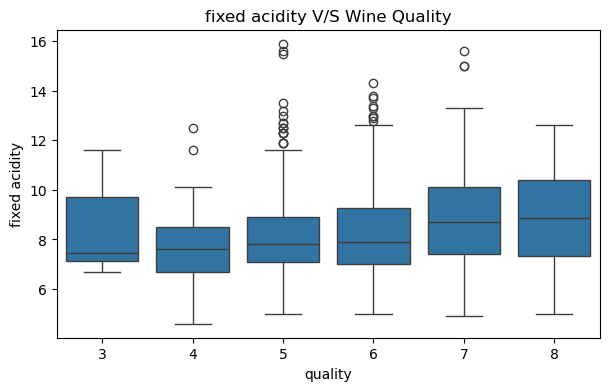

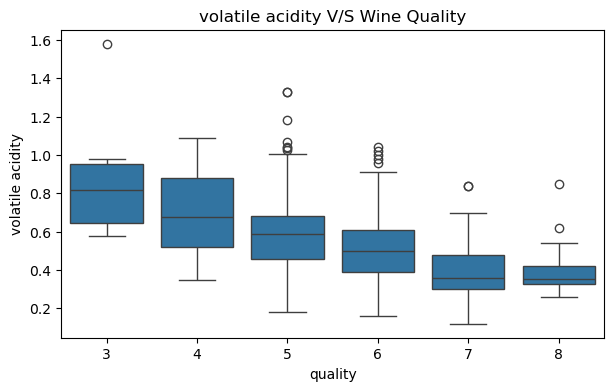

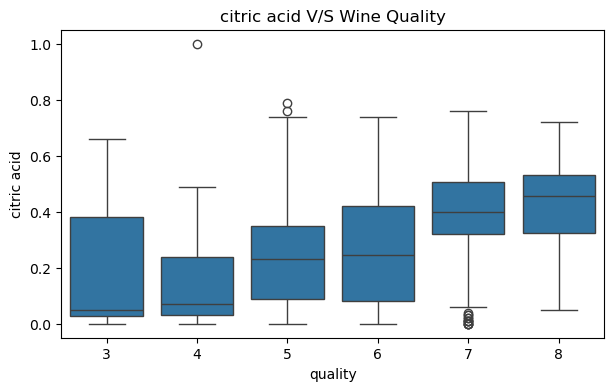

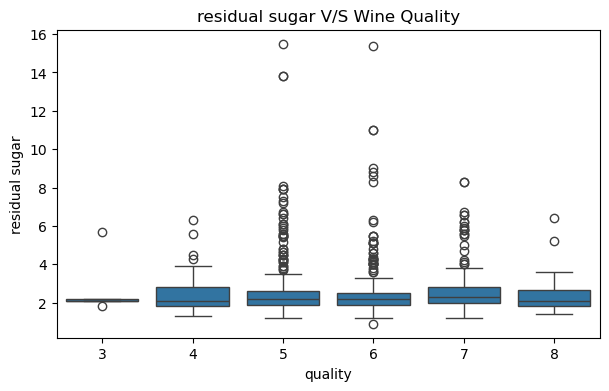

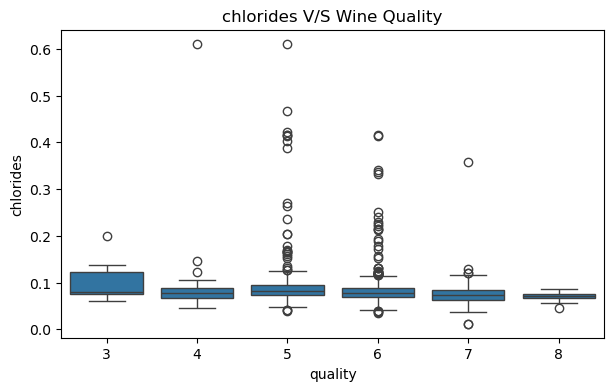

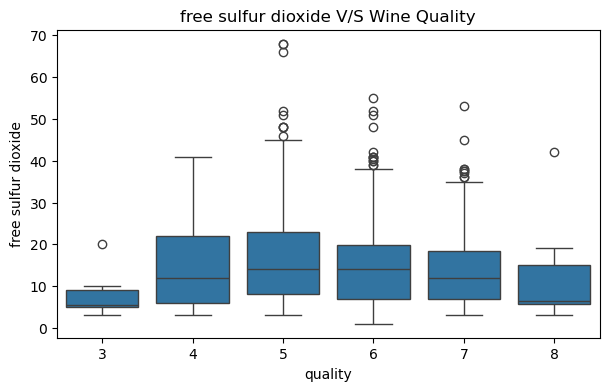

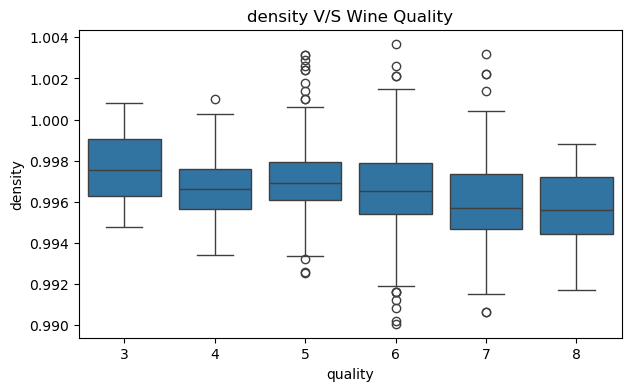

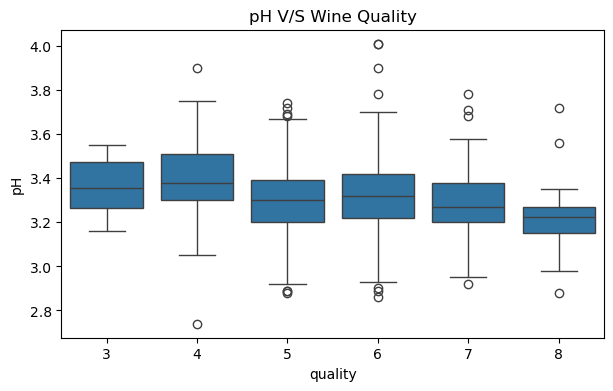

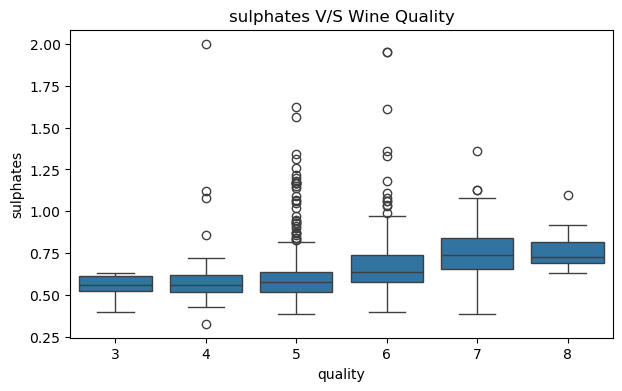

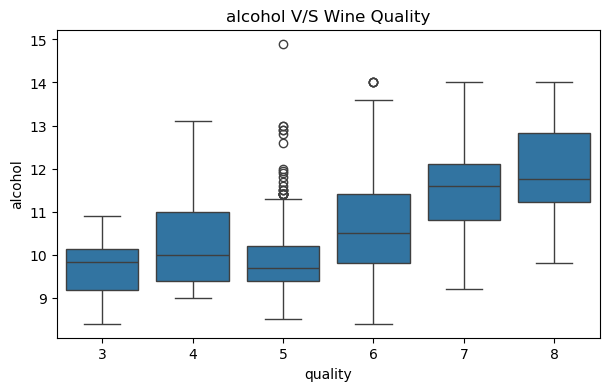

In [91]:
features=['fixed acidity','volatile acidity','citric acid','residual sugar','chlorides','free sulfur dioxide','density',
          'pH','sulphates','alcohol']
for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='quality',y=col,data=df)
    plt.title(f'{col} V/S Wine Quality')
    plt.show()

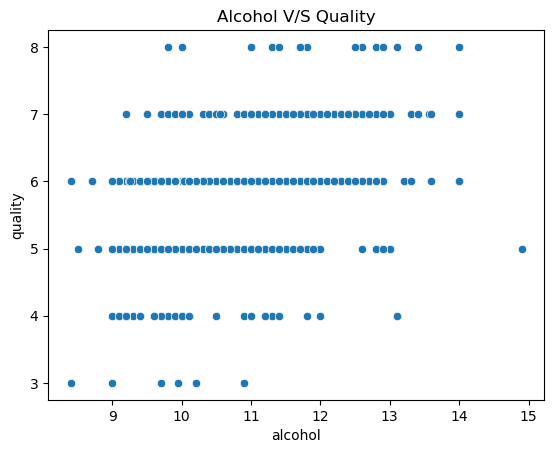

In [92]:
sns.scatterplot(x='alcohol',y='quality',data=df)
plt.title('Alcohol V/S Quality')
plt.show()

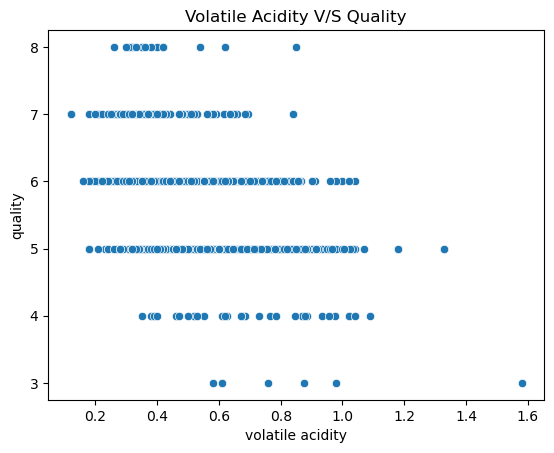

In [93]:
sns.scatterplot(x='volatile acidity',y='quality',data=df)
plt.title('Volatile Acidity V/S Quality')
plt.show()

3.Multivariete Analysis

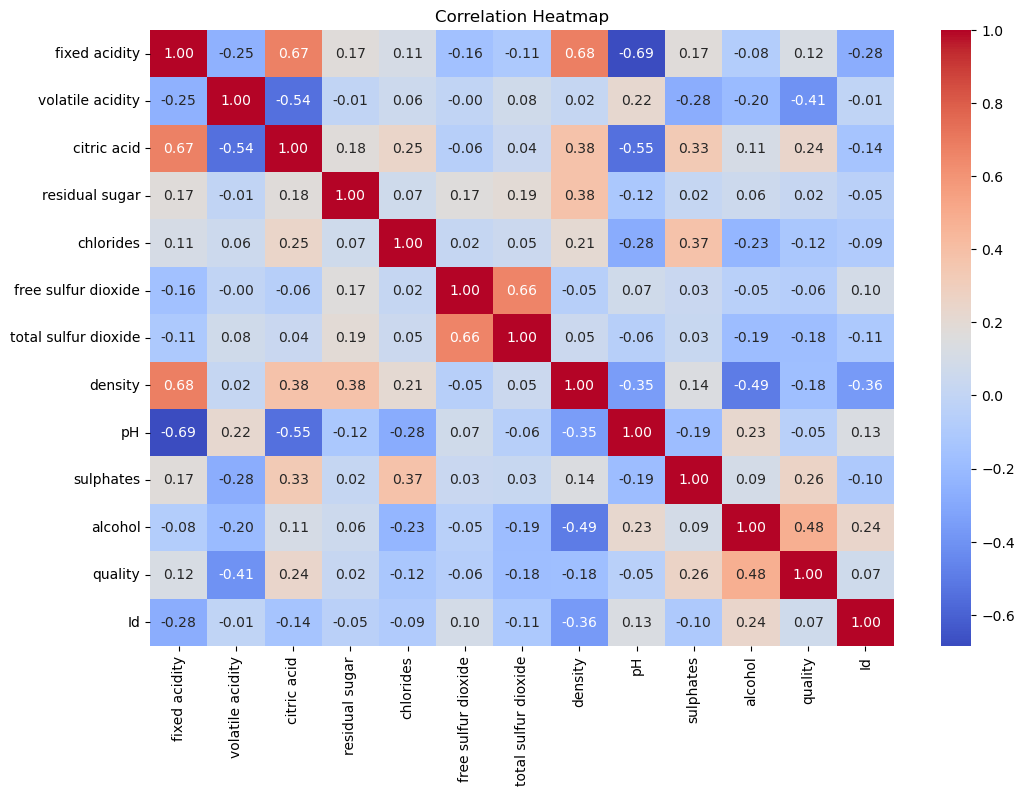

In [94]:
plt.figure(figsize=(12,8))
corr=df.corr()
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show() 

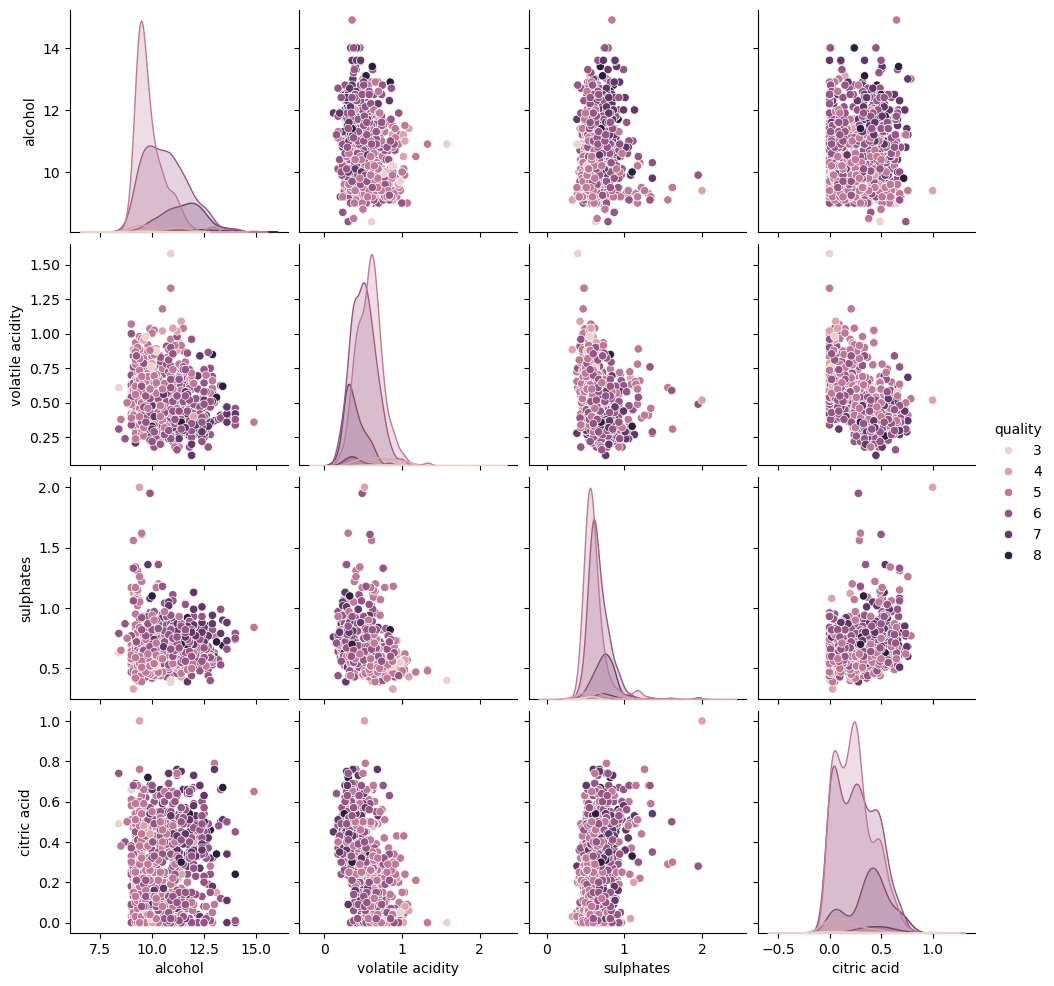

In [95]:
selected=['alcohol','volatile acidity','sulphates','citric acid','quality']
sns.pairplot(df[selected],hue='quality')
plt.show()

In [96]:
df['quality_group'] = pd.cut(
    df['quality'],
    bins=[0, 5, 6, 10],
    labels=['Low', 'Medium', 'High']
)

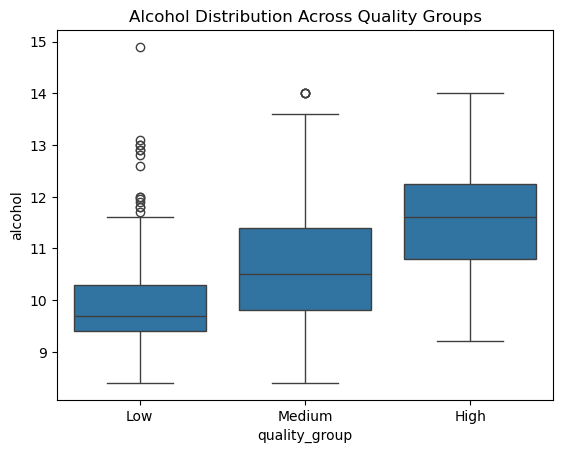

In [97]:
sns.boxplot(
    x='quality_group',
    y='alcohol',
    data=df
)
plt.title('Alcohol Distribution Across Quality Groups')
plt.show()

In [98]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,
                            ConfusionMatrixDisplay)


In [99]:
X=df.drop('quality',axis=1)
y=df['quality']

In [100]:
print("X shape:'",X.shape)
print("y shape:",y.shape)

X shape:' (1143, 13)
y shape: (1143,)


In [101]:
print(y.value_counts().sort_index())

quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


In [102]:
X_train,y_train,X_test,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [103]:
criterion='entropy'

In [104]:
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)

In [105]:
df['quality_group']=pd.cut(
    df['quality'],
    bins=[0,5,6,10],
    labels=['Low','Medium','High'])

In [106]:
print(X.columns)
print(X.dtypes)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'Id', 'quality_group'],
      dtype='object')
fixed acidity            float64
volatile acidity         float64
citric acid              float64
residual sugar           float64
chlorides                float64
free sulfur dioxide      float64
total sulfur dioxide     float64
density                  float64
pH                       float64
sulphates                float64
alcohol                  float64
Id                         int64
quality_group           category
dtype: object


In [107]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [108]:
X = df.drop(['quality', 'quality_group'], axis=1)

In [109]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)


X_train: (914, 13)
X_test: (229, 13)
y_train: (914,)
y_test: (229,)


In [110]:
X = df.drop(['quality', 'quality_group'], axis=1)
y = df['quality'] 
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [111]:
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)
dt_model.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [112]:
dt_model.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [113]:
y_train_pred=dt_model.predict(X_train)
y_test_pred=dt_model.predict(X_test)

In [114]:
train_accuracy=accuracy_score(y_train,y_train_pred)
print("Training Accuracy;",train_accuracy)

Training Accuracy; 1.0


In [115]:
test_accuracy=accuracy_score(y_test,y_test_pred)
print("Test Accuracy;",test_accuracy)

Test Accuracy; 0.6200873362445415


In [116]:
print("Precision:", precision_score(y_test, y_test_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_test_pred, average='weighted'))
print("F1 Score:", f1_score(y_test, y_test_pred, average='weighted'))

Precision: 0.6070017244204808
Recall: 0.6200873362445415
F1 Score: 0.6099421427959831


In [117]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.20      0.14      0.17         7
           5       0.69      0.80      0.74        97
           6       0.62      0.52      0.56        92
           7       0.48      0.52      0.50        29
           8       0.00      0.00      0.00         3

    accuracy                           0.62       229
   macro avg       0.33      0.33      0.33       229
weighted avg       0.61      0.62      0.61       229



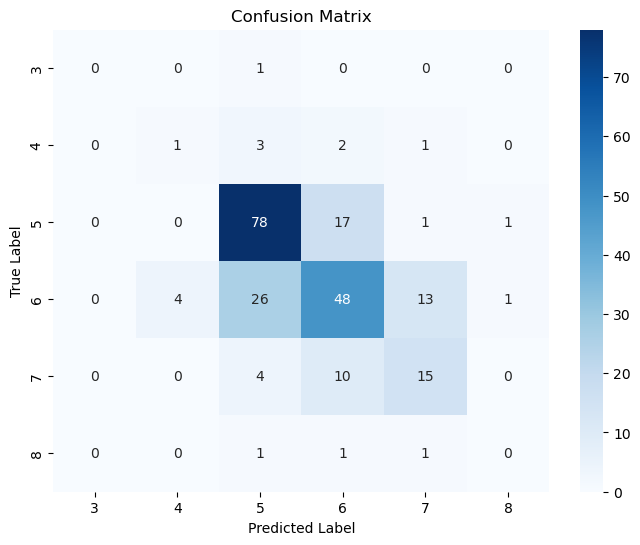

In [118]:
# Confusion Matrix 
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=np.unique(y_test), 
            yticklabels=np.unique(y_test))
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [119]:
print("Tree Depth: ",dt_model.get_depth())
print("Number of Leaves:",dt_model.get_n_leaves())

Tree Depth:  18
Number of Leaves: 236


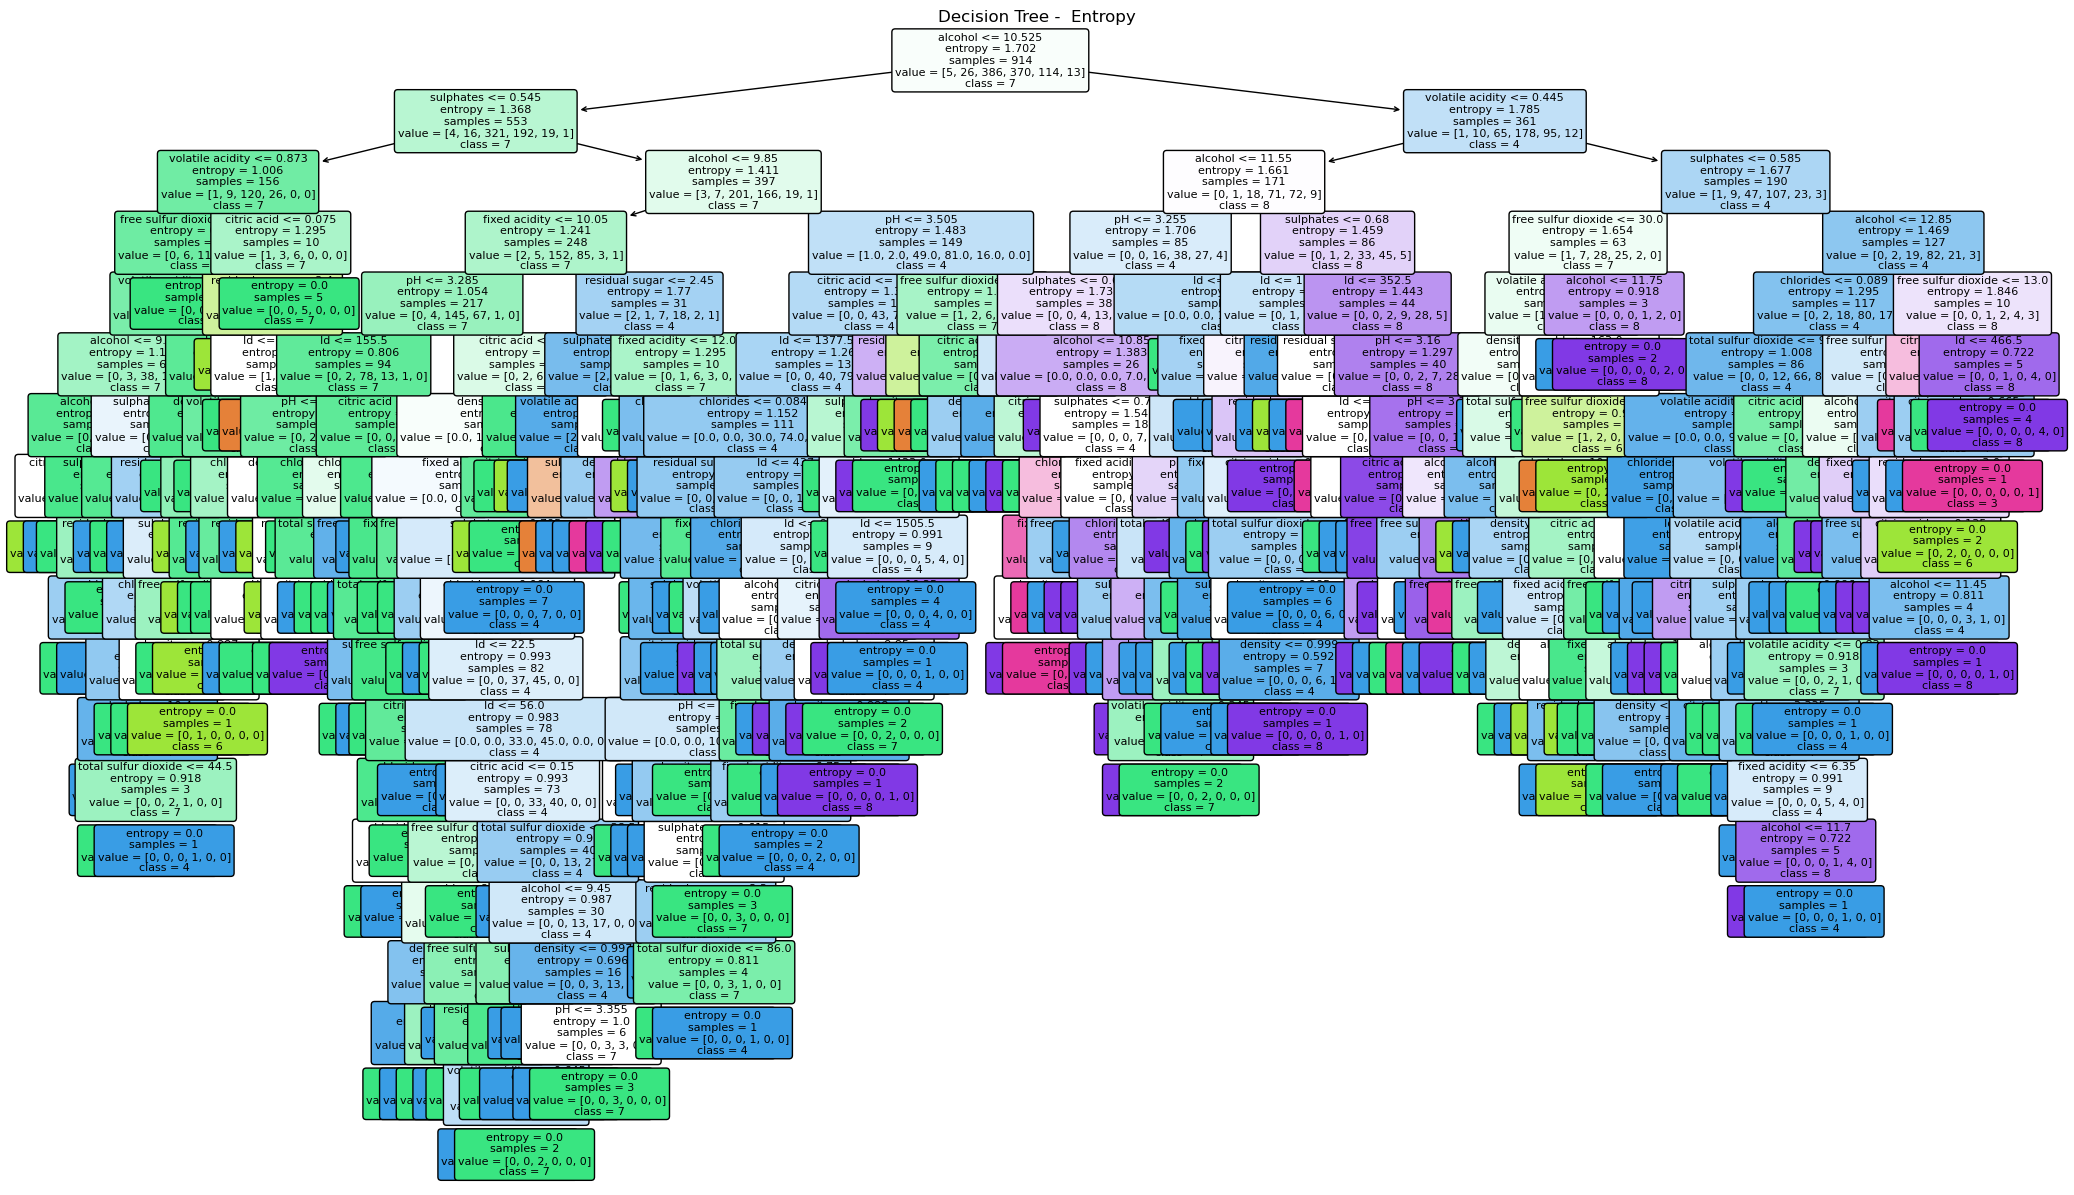

In [120]:
plt.figure(figsize=(25,15))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in (y.unique())],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree -  Entropy")
plt.show()

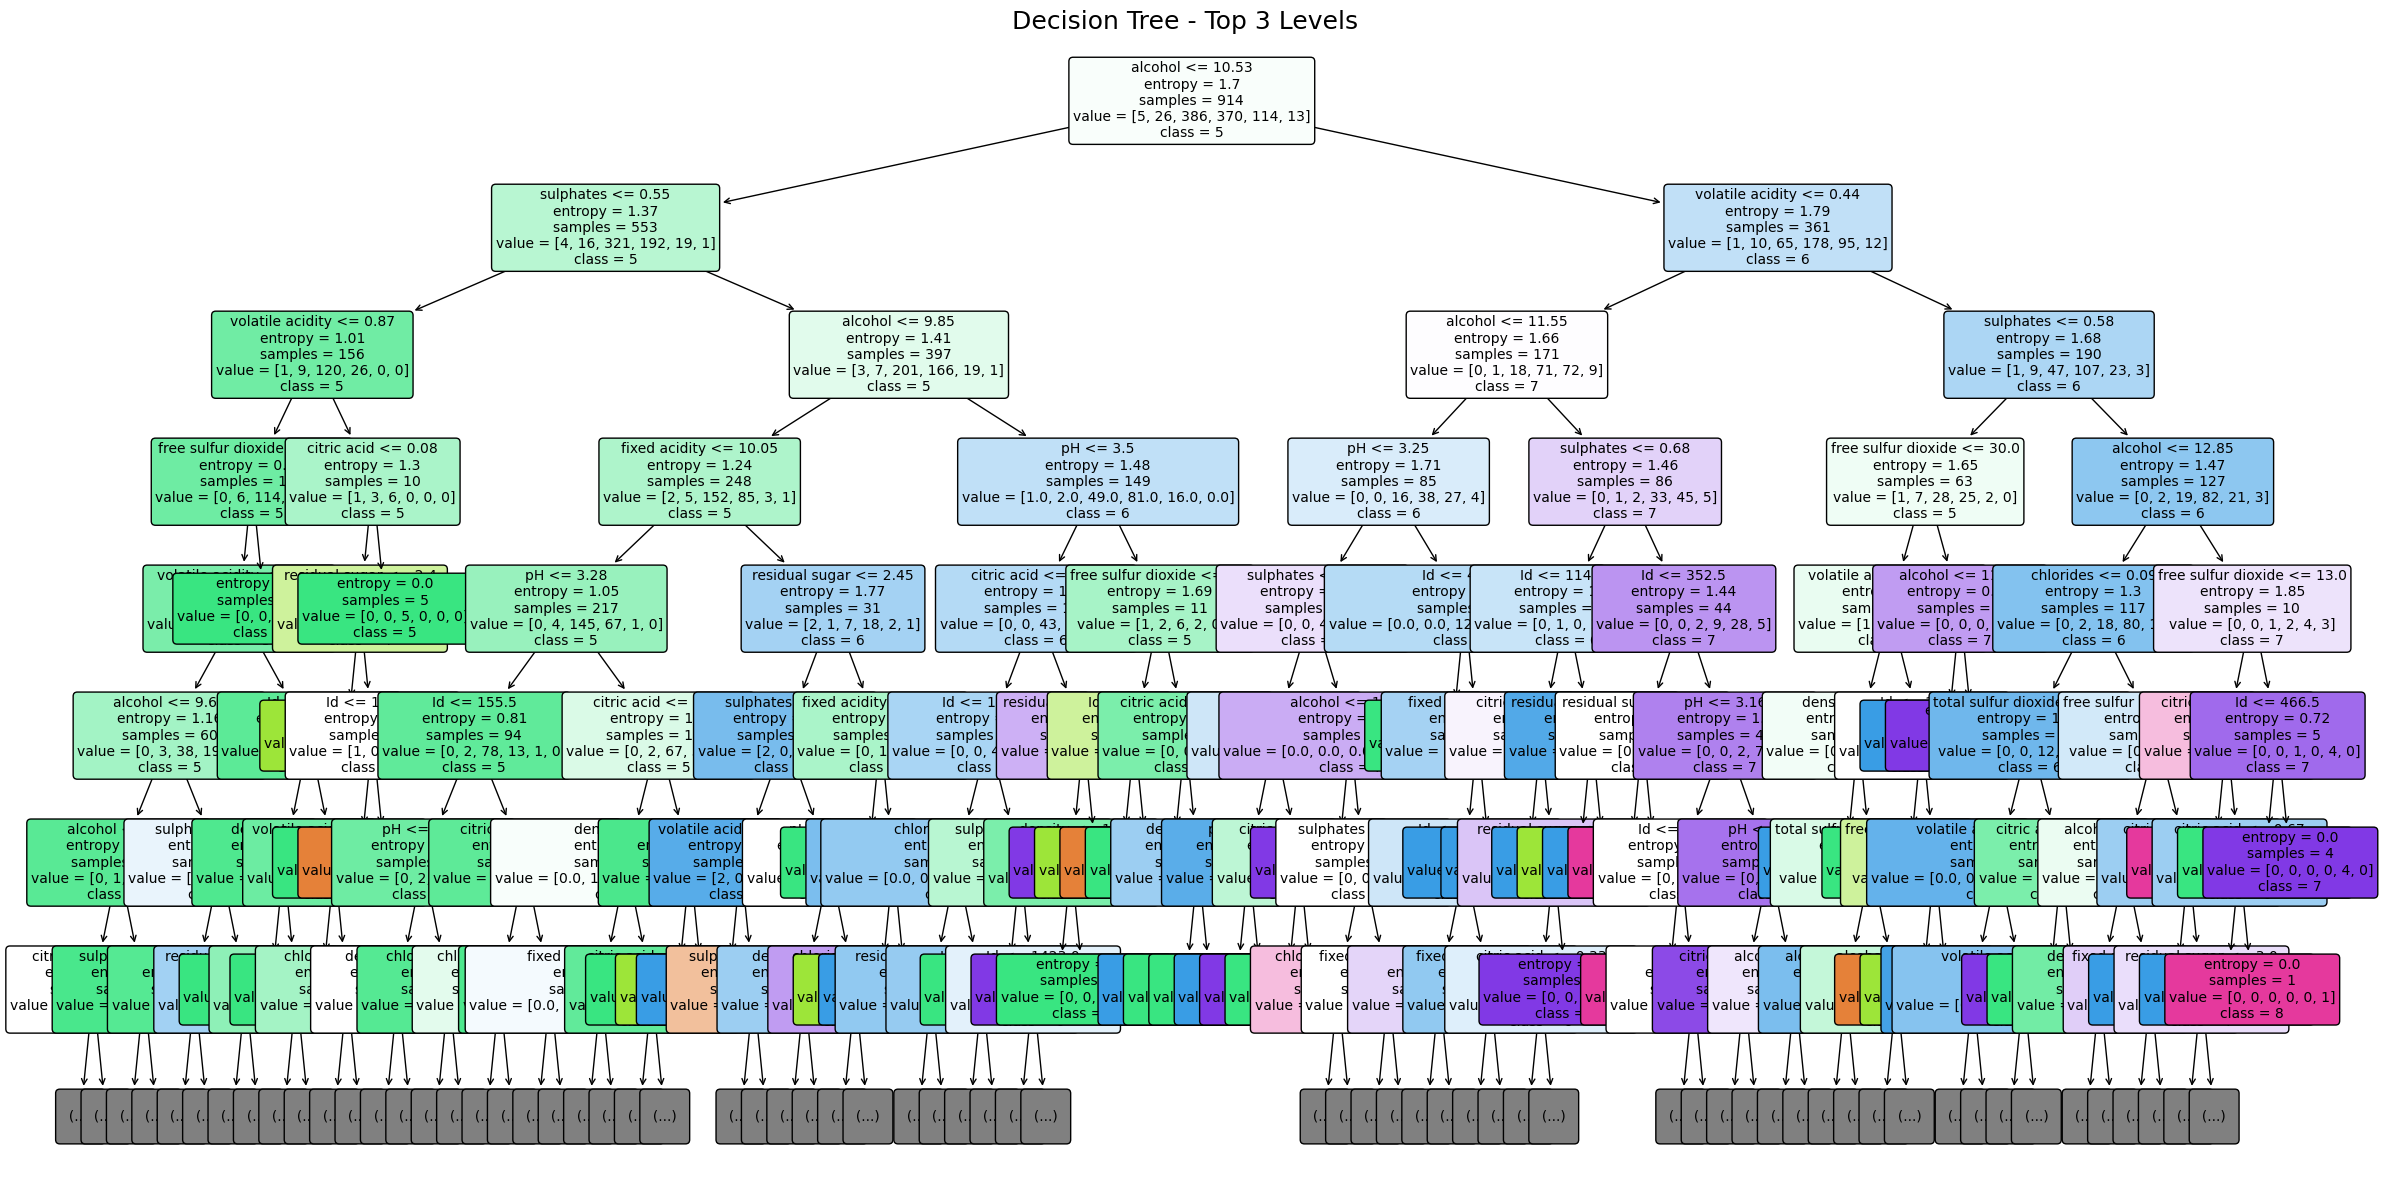

In [121]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize=(24,12))
plot_tree(dt_model,feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],filled=True,
          rounded=True,
    impurity=True,precision=2,fontsize=10,max_depth=7
         )
plt.title("Decision Tree - Top 3 Levels",fontsize=18)
plt.tight_layout()
plt.show()

AUC ROC CURVE

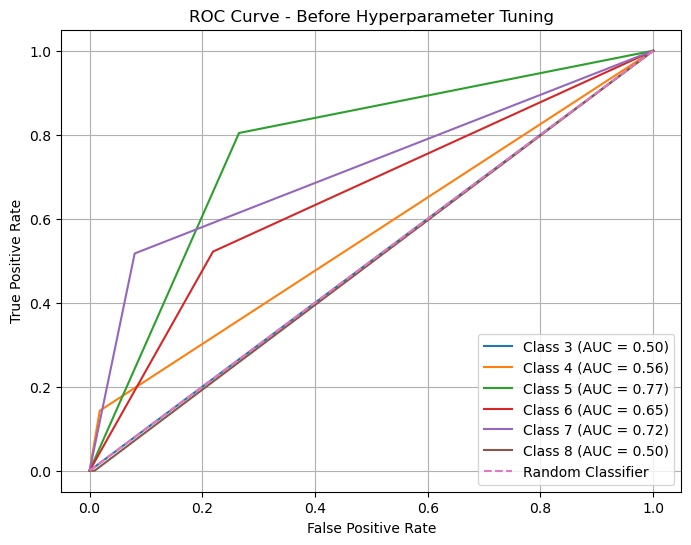

Overall ROC-AUC Before Tuning: 0.7045


In [123]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

y_score = dt_model.predict_proba(X_test)
classes = dt_model.classes_
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8, 6))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {cls} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Before Hyperparameter Tuning')
plt.legend()
plt.grid()
plt.show()

overall_auc_before = roc_auc_score(y_test_bin, y_score, multi_class='ovr', average='weighted')
print("Overall ROC-AUC Before Tuning:", round(overall_auc_before, 4))

Hyperparameter Tuning

In [124]:
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings('ignore')
param_grid = {
    'criterion': ['entropy', 'gini'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2'],
    'ccp_alpha': [0.0, 0.005, 0.01]
}
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42), 
    param_grid, 
    cv=5, 
    scoring='accuracy', 
    n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best Parameters:")
print(grid.best_params_)
print("Best Cross-Validation Score:", round(grid.best_score_, 4))

Best Parameters:
{'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2}
Best Cross-Validation Score: 0.5821


In [126]:
best_tree = grid.best_estimator_
y_pred=best_tree.predict(X_test)
print(classification_report(y_test,y_pred))
print("Accuracy=" ,accuracy_score(y_test,y_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.67      0.82      0.74        97
           6       0.58      0.52      0.55        92
           7       0.46      0.38      0.42        29
           8       0.00      0.00      0.00         3

    accuracy                           0.61       229
   macro avg       0.28      0.29      0.28       229
weighted avg       0.57      0.61      0.59       229

Accuracy= 0.6069868995633187


In [127]:
train_accuracy=best_tree.score(X_train,y_train)
test_accuracy=best_tree.score(X_test,y_test)
print("Testing Accuracy=",train_accuracy)
print("Testing Accuracy=",test_accuracy)

Testing Accuracy= 0.6914660831509847
Testing Accuracy= 0.6069868995633187


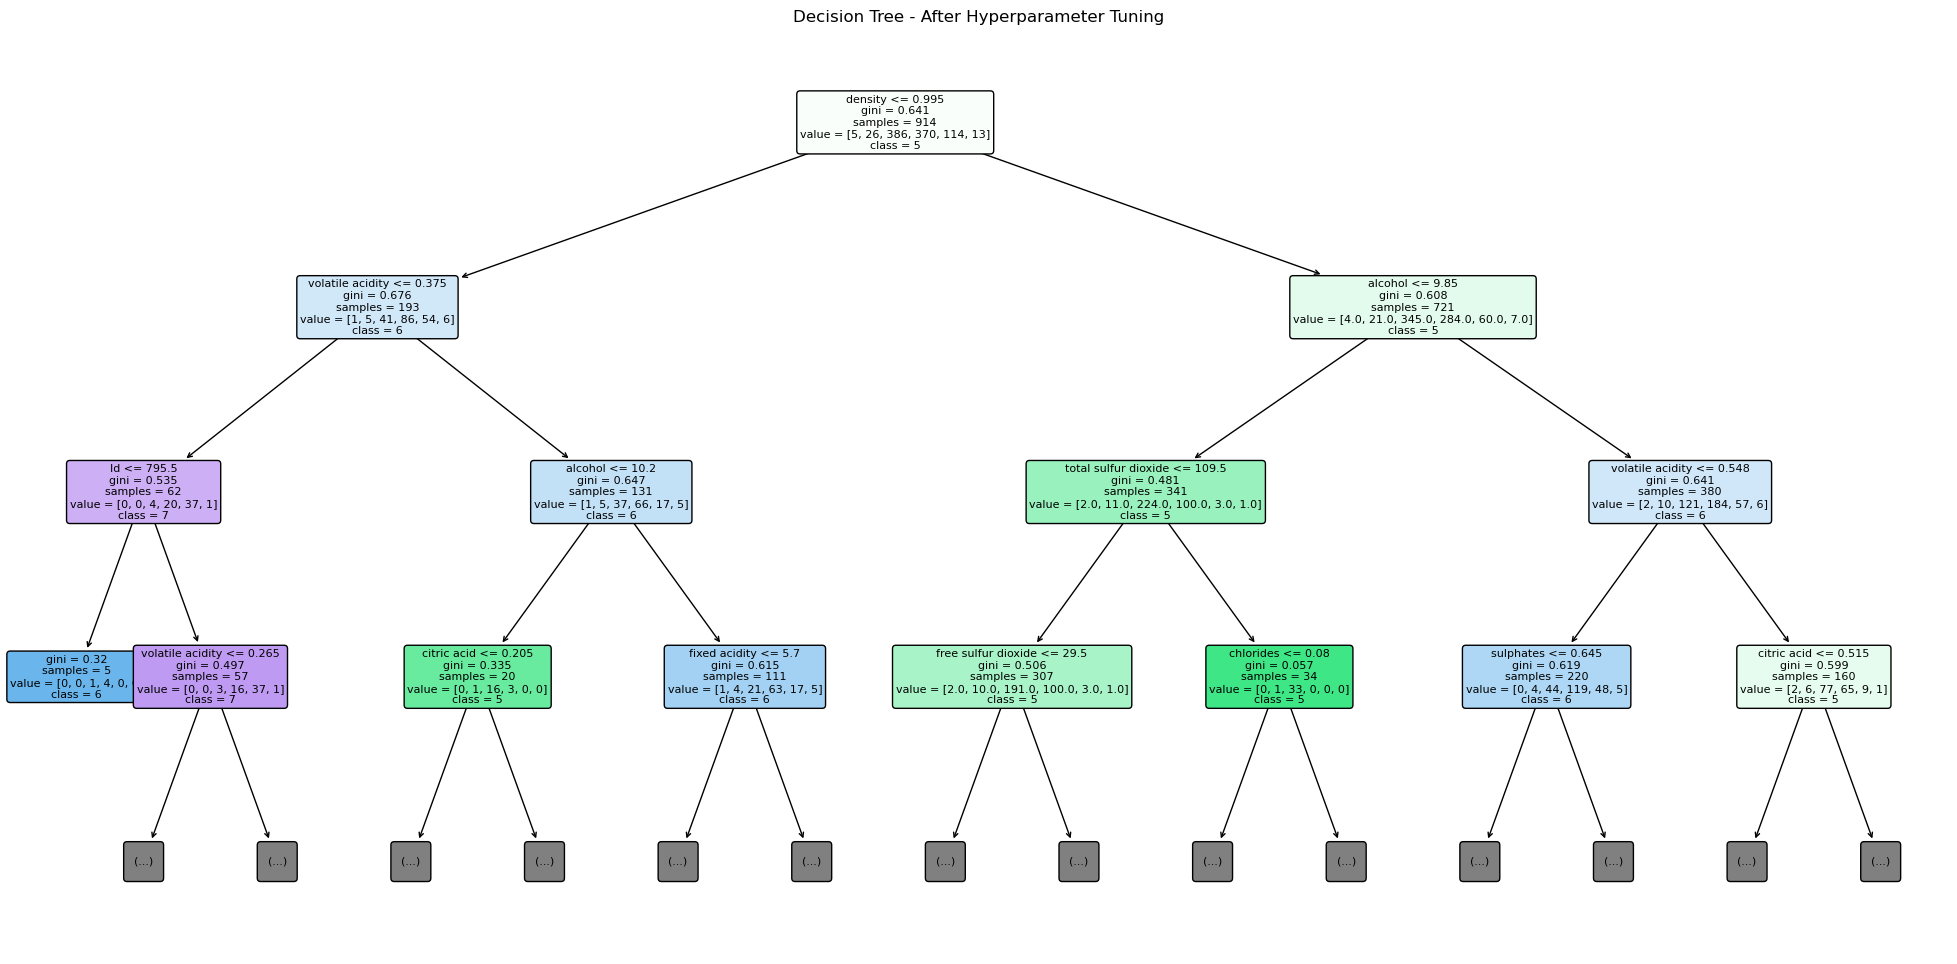

In [133]:
from sklearn.tree import plot_tree
plt.figure(figsize=(25,12))
plot_tree(
    best_tree,
    feature_names=X.columns,
    class_names=[str(c) for c in best_tree.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree - After Hyperparameter Tuning")
plt.show()


Cross Validation

In [134]:
from sklearn.model_selection import cross_val_score
scores=cross_val_score(best_tree,X,y,cv=10,scoring='accuracy')
print(scores)
print("Average Accuracy=",scores.mean())
print("Std=",scores.std())

[0.47826087 0.43478261 0.52173913 0.51754386 0.45614035 0.59649123
 0.52631579 0.51754386 0.55263158 0.4122807 ]
Average Accuracy= 0.5013729977116704
Std= 0.05309116271731559


Learning Curve

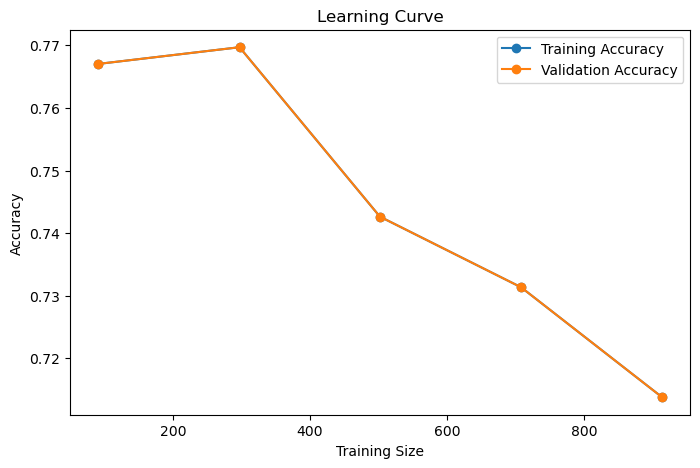

In [138]:
from sklearn.model_selection import learning_curve
train_sizes,train_scores,test_score=learning_curve(best_tree,X,y,cv=5,scoring='accuracy')
plt.figure(figsize=(8,5))
plt.plot(train_sizes,train_scores.mean(axis=1),marker='o',label='Training Accuracy')
plt.plot(train_sizes,train_scores.mean(axis=1),marker='o',label='Validation Accuracy')
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()
plt.show()

In [143]:
new_wine = pd.DataFrame([{
    'fixed acidity': 7.4,
    'volatile acidity': 0.70,
    'citric acid': 0.00,
    'residual sugar': 1.9,
    'chlorides': 0.076,
    'free sulfur dioxide': 11.0,
    'total sulfur dioxide': 34.0,
    'density': 0.9978,
    'pH': 3.51,
    'sulphates': 0.56,
    'alcohol': 10,
    'Id': 0
}])
prediction= best_tree.predict(new_wine)
print("Predicted Wine Quality:",prediction[0])

Predicted Wine Quality: 5
